# Листок № 1. СЛАУ, матрицы и квадратичные формы

Решения заданий **1.1–1.20** из файла «Практические занятия Листок 1.pdf».
В этом листке нет распределения по вариантам, поэтому выполнены все задания,
включая пункты со звёздочками.

Для точных преобразований используется SymPy, для численных расчётов — NumPy,
для рисунков — Matplotlib. После каждого вычисления приведён результат;
ключевые равенства дополнительно проверяются подстановкой.

**Замечание к условию.** В № 1.20 в PDF напечатано $2x_1$ вместо ожидаемого
$2x_1^2$. В соответствующем разделе отдельно разобраны буквальная запись
и трактовка выражения как квадратичной формы.

Ячейки выполняются последовательно: **Kernel → Restart Kernel and Run All Cells**.

In [1]:
import math
from itertools import combinations

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from IPython.display import display, Markdown

sp.init_printing()
np.set_printoptions(precision=10, suppress=True)
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
})
answers = {}

def show(label, expression):
    display(Markdown(f'**{label}**'))
    display(expression)

## 1.1. Общее решение СЛАУ

$$\begin{cases}
x_1+5x_2-2x_3=-7,\\
-3x_1+x_2+9x_3-5x_4=9,\\
4x_1-8x_2-x_3+7x_4=0.
\end{cases}$$

Приведём расширенную матрицу к ступенчатому виду. Три ведущих столбца
соответствуют $x_1,x_2,x_3$, поэтому $x_4=t$ — свободный параметр:

$$x=\left(-\frac{11+8t}{7},\frac{-6+2t}{7},\frac{4+t}{7},t\right),
\qquad t\in\mathbb R.$$

In [2]:
A1 = sp.Matrix([[1, 5, -2, 0], [-3, 1, 9, -5], [4, -8, -1, 7]])
b1 = sp.Matrix([-7, 9, 0])
R1, pivots1 = A1.row_join(b1).rref()
t = sp.symbols('t', real=True)
solution1 = sp.Matrix([-(11 + 8*t)/7, (-6 + 2*t)/7, (4 + t)/7, t])
show('Приведённая расширенная матрица', R1)
show('Общее решение', solution1)
assert sp.simplify(A1 * solution1 - b1) == sp.zeros(3, 1)
assert A1.rank() == A1.row_join(b1).rank() == 3
print('Подстановка даёт нулевую невязку для любого t.')
answers['1.1'] = '(-(11+8t)/7, (-6+2t)/7, (4+t)/7, t)'

**Приведённая расширенная матрица**

⎡1  0  0  8/7   -11/7⎤
⎢                    ⎥
⎢0  1  0  -2/7  -6/7 ⎥
⎢                    ⎥
⎣0  0  1  -1/7   4/7 ⎦

**Общее решение**

⎡  8⋅t   11⎤
⎢- ─── - ──⎥
⎢   7    7 ⎥
⎢          ⎥
⎢ 2⋅t   6  ⎥
⎢ ─── - ─  ⎥
⎢  7    7  ⎥
⎢          ⎥
⎢  t   4   ⎥
⎢  ─ + ─   ⎥
⎢  7   7   ⎥
⎢          ⎥
⎣    t     ⎦

Подстановка даёт нулевую невязку для любого t.


## 1.2. RREF и два свободных параметра

$$\begin{cases}
5x_1-x_2+5x_3+9x_4-2x_5=-3,\\
3x_1+6x_3+9x_4-x_5=4,\\
2x_1+4x_3+6x_4-x_5=0.
\end{cases}$$

После приведения расширенной матрицы ведущими оказываются столбцы
$x_1,x_2,x_5$. Положив $x_3=s$, $x_4=t$, получим

$$x=(4-2s-3t,\;7-5s-6t,\;s,\;t,\;8),\qquad s,t\in\mathbb R.$$

In [3]:
A2 = sp.Matrix([[5, -1, 5, 9, -2], [3, 0, 6, 9, -1], [2, 0, 4, 6, -1]])
b2 = sp.Matrix([-3, 4, 0])
R2, pivots2 = A2.row_join(b2).rref()
s, t = sp.symbols('s t', real=True)
solution2 = sp.Matrix([4-2*s-3*t, 7-5*s-6*t, s, t, 8])
show('RREF', R2)
show('Общее решение', solution2)
assert pivots2 == (0, 1, 4)
assert A2 * solution2 - b2 == sp.zeros(3, 1)
print('Два свободных параметра; все три уравнения выполнены тождественно.')
answers['1.2'] = '(4−2s−3t, 7−5s−6t, s, t, 8)'

**RREF**

⎡1  0  2  3  0  4⎤
⎢                ⎥
⎢0  1  5  6  0  7⎥
⎢                ⎥
⎣0  0  0  0  1  8⎦

**Общее решение**

⎡-2⋅s - 3⋅t + 4⎤
⎢              ⎥
⎢-5⋅s - 6⋅t + 7⎥
⎢              ⎥
⎢      s       ⎥
⎢              ⎥
⎢      t       ⎥
⎢              ⎥
⎣      8       ⎦

Два свободных параметра; все три уравнения выполнены тождественно.


## 1.3. Зависимость $y$ от $x$

$$\begin{cases}
32x+97y+90z+48u=47,\\
35x+84y+91z+54u=40,\\
17x+18y+21z+13u=37.
\end{cases}$$

Перенесём слагаемые с $x$ вправо. Матрица коэффициентов при $(y,z,u)$
обратима, поэтому для любого $x$ существует единственная тройка
$(y,z,u)^T=C^{-1}(b-xd)$. Это аффинная функция $x$.
Из её первой координаты найдём $a$ и $b$ в записи $y=a+bx$.

In [4]:
x = sp.symbols('x', real=True)
C3 = sp.Matrix([[97, 90, 48], [84, 91, 54], [18, 21, 13]])
d3 = sp.Matrix([32, 35, 17])
b3 = sp.Matrix([47, 40, 37])
dependent3 = C3.inv() * (b3 - x*d3)
show('det C', C3.det())
show('(y, z, u)', dependent3)
a3 = dependent3[0].subs(x, 0)
bcoef3 = sp.diff(dependent3[0], x)
assert sp.simplify(C3 * dependent3 + x*d3 - b3) == sp.zeros(3, 1)
print(f'y = {a3} + ({bcoef3}) x;  a = {a3}, b = {bcoef3}')
answers['1.3'] = f'a = {a3}, b = {bcoef3}'

**det C**

**(y, z, u)**

⎡14027 - 4262⋅x ⎤
⎢               ⎥
⎢10447⋅x - 34382⎥
⎢               ⎥
⎣36121 - 10976⋅x⎦

y = 14027 + (-4262) x;  a = 14027, b = -4262


## 1.4. Произведение и сумма матриц

Вычислим $AB+C$, где

$$A=\begin{pmatrix}3&0&2\\0&1&3\\2&2&0\\0&1&0\end{pmatrix},\quad
B=\begin{pmatrix}1&2&-1&2\\-2&-1&1&2\\2&1&1&2\end{pmatrix},\quad
C=\begin{pmatrix}0&-4&6&1\\2&2&-5&-2\\2&-2&6&4\\1&3&0&1\end{pmatrix}.$$

Размеры согласованы: $(4\times3)(3\times4)+(4\times4)$.

In [5]:
A4 = sp.Matrix([[3,0,2], [0,1,3], [2,2,0], [0,1,0]])
B4 = sp.Matrix([[1,2,-1,2], [-2,-1,1,2], [2,1,1,2]])
C4 = sp.Matrix([[0,-4,6,1], [2,2,-5,-2], [2,-2,6,4], [1,3,0,1]])
result4 = A4 * B4 + C4
show('AB + C', result4)
manual4 = sp.Matrix(4, 4, lambda i,j: sum(A4[i,k]*B4[k,j] for k in range(3)) + C4[i,j])
assert result4 == manual4
answers['1.4'] = str(result4.tolist())

**AB + C**

⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦

## 1.5. Три семейства определителей

**а) $a_{ij}=\min(i,j)$.** Пусть $L$ — нижнетреугольная матрица из единиц
на диагонали и ниже неё. Тогда $A=LL^T$, поэтому $\det A=1$.

**б) $a_{ij}=\max(i,j)$.** Начиная снизу заменим строку $i$ разностью
строк $i$ и $i-1$. В строках $2,\ldots,n$ единицы стоят в первых $i-1$
столбцах, остальные элементы нулевые. В последнем столбце остаётся только
элемент $n$ первой строки. Разложение по этому столбцу даёт
$\det A=(-1)^{n-1}n$.

**в) $a_{ij}=|i-j|$.** Выполним те же разности строк и столбцов.
Обе преобразующие матрицы имеют определитель 1. Получится
$$\begin{pmatrix}0&\mathbf1^T\\\mathbf1&-2I_{n-1}\end{pmatrix}.$$
По формуле дополнения Шура при $n\ge2$ её определитель равен
$$(-2)^{n-1}\left(\frac{n-1}{2}\right)
=(-1)^{n-1}(n-1)2^{n-2}.$$
При $n=1$ определитель матрицы расстояний равен нулю.

In [6]:
for n in range(1, 9):
    minimum = sp.Matrix(n, n, lambda i,j: min(i+1, j+1))
    maximum = sp.Matrix(n, n, lambda i,j: max(i+1, j+1))
    distance = sp.Matrix(n, n, lambda i,j: abs(i-j))
    formulas = (1, (-1)**(n-1)*n,
                0 if n == 1 else (-1)**(n-1)*(n-1)*2**(n-2))
    actual = tuple(M.det() for M in (minimum, maximum, distance))
    assert actual == formulas
    print(f'n={n}: det(min)={str(actual[0]):>2}, det(max)={str(actual[1]):>3}, det(|i−j|)={actual[2]}')
answers['1.5'] = '1; (−1)^(n−1)n; (−1)^(n−1)(n−1)2^(n−2), n≥2 (при n=1: 0)'

n=1: det(min)= 1, det(max)=  1, det(|i−j|)=0
n=2: det(min)= 1, det(max)= -2, det(|i−j|)=-1
n=3: det(min)= 1, det(max)=  3, det(|i−j|)=4
n=4: det(min)= 1, det(max)= -4, det(|i−j|)=-12
n=5: det(min)= 1, det(max)=  5, det(|i−j|)=32
n=6: det(min)= 1, det(max)= -6, det(|i−j|)=-80
n=7: det(min)= 1, det(max)=  7, det(|i−j|)=192
n=8: det(min)= 1, det(max)= -8, det(|i−j|)=-448


## 1.6. Максимальный определитель порядка 6

Нужно найти максимальный определитель матрицы с элементами из $\{-1,0,1\}$.
По каждому элементу отдельно определитель — линейная функция. Поэтому
модуль определителя на кубе $[-1,1]^{36}$ достигает максимума в вершине:
нули не позволяют превзойти максимум для матриц из $\{-1,1\}$.

Умножением строк и столбцов на $-1$ сделаем первую строку и первый столбец
равными 1, сохранив модуль определителя. После вычитания первой строки
из остальных получаем $|\det H|=2^5|\det B|$, где $B$ — двоичная матрица
порядка 5. При ненулевом определителе её строки различны и ненулевые.
Порядок строк влияет только на знак, поэтому достаточно перебрать
$\binom{31}{5}=169\,911$ наборов строк.

В переборе используется **целочисленный алгоритм Барейса**, без округления
численных определителей. Он даёт $\max|\det B|=5$, следовательно,
максимальный определитель порядка 6 равен **160**. Ниже также строится
матрица, на которой достигается положительное значение 160.

In [7]:
def integer_determinant(rows):
    """Точный определитель: исключение Барейса с перестановками строк."""
    a = [list(row) for row in rows]
    size = len(a)
    previous, sign = 1, 1
    for k in range(size - 1):
        pivot_row = next((i for i in range(k, size) if a[i][k] != 0), None)
        if pivot_row is None:
            return 0
        if pivot_row != k:
            a[k], a[pivot_row] = a[pivot_row], a[k]
            sign = -sign
        pivot = a[k][k]
        for i in range(k + 1, size):
            for j in range(k + 1, size):
                a[i][j] = (pivot*a[i][j] - a[i][k]*a[k][j]) // previous
            a[i][k] = 0
        previous = pivot
    return sign * a[-1][-1]

binary_rows = [tuple((mask >> j) & 1 for j in range(5)) for mask in range(1, 32)]
best_binary_det, witness_rows, checked = 0, None, 0
for rows in combinations(binary_rows, 5):
    value = abs(integer_determinant(rows))
    checked += 1
    if value > best_binary_det:
        best_binary_det, witness_rows = value, rows

binary_witness = sp.Matrix(witness_rows)
H6 = sp.ones(6)
H6[1:, 1:] = sp.ones(5) - 2*binary_witness
if H6.det() < 0:
    H6[0, :] = -H6[0, :]
assert checked == math.comb(31, 5) == 169911
assert best_binary_det == abs(binary_witness.det()) == 5
assert H6.det() == 160
assert set(H6).issubset({-1, 1})
print(f'Проверено наборов: {checked}; максимум |det B| = {best_binary_det}')
show('Матрица с det H = 160', H6)
show('Точный определитель', H6.det())
answers['1.6'] = '160'

Проверено наборов: 169911; максимум |det B| = 5


**Матрица с det H = 160**

⎡-1  -1  -1  -1  -1  -1⎤
⎢                      ⎥
⎢1   -1  -1  1   1   1 ⎥
⎢                      ⎥
⎢1   -1  1   -1  1   1 ⎥
⎢                      ⎥
⎢1   1   -1  -1  -1  1 ⎥
⎢                      ⎥
⎢1   1   -1  -1  1   -1⎥
⎢                      ⎥
⎣1   -1  1   1   -1  -1⎦

**Точный определитель**

## 1.7. Матрица порядка 80 000

Пусть $d_i=0.99+0.02(i-1)/(n-1)$, $n=80\,000$.
Все внедиагональные элементы нулевые, кроме $a_{12}=0.57$, $a_{21}=0.03$.
Следовательно, матрица состоит из блока $2\times2$ и диагонального блока:

$$\det A=(d_1d_2-0.57\cdot0.03)\prod_{i=3}^n d_i,$$
$$\operatorname{tr}(A^{-1})=
\frac{d_1+d_2}{d_1d_2-0.57\cdot0.03}+\sum_{i=3}^n\frac1{d_i}.$$

Произведение вычислим через сумму логарифмов. Храним только диагональ:
для решения достаточно $O(n)$ памяти, полная матрица не нужна.

In [8]:
n7 = 80000
diagonal7 = np.linspace(0.99, 1.01, n7)
block_det7 = diagonal7[0]*diagonal7[1] - 0.57*0.03
det7 = np.exp(np.log(block_det7) + np.log(diagonal7[2:]).sum())
trace7 = (diagonal7[0]+diagonal7[1])/block_det7 + np.sum(1/diagonal7[2:])
print(f'det A = {det7:.12f} ≈ {det7:.3f}')
print(f'tr(A⁻¹) = {trace7:.9f} ≈ {trace7:.3f}')
# Независимая проверка формул на небольшой матрице той же структуры.
small_d7 = np.linspace(0.99, 1.01, 9)
small_A7 = np.diag(small_d7)
small_A7[0,1], small_A7[1,0] = 0.57, 0.03
small_block7 = small_d7[0]*small_d7[1] - 0.57*0.03
assert np.isclose(np.linalg.det(small_A7), small_block7*np.prod(small_d7[2:]))
assert np.isclose(np.trace(np.linalg.inv(small_A7)),
                  sum(1/small_d7[2:]) + sum(small_d7[:2])/small_block7)
answers['1.7'] = f'det A ≈ {det7:.9f}; tr(A⁻¹) ≈ {trace7:.6f}'

det A = 0.258979113865 ≈ 0.259
tr(A⁻¹) = 80002.702766086 ≈ 80002.703


## 1.8. Обратная матрица порядка 43 000

Диагональ образует геометрическую прогрессию от 1 до 1.07, первая строка —
арифметическую от 1 до 1.10. Обозначим
$$d_j=1.07^{(j-1)/(n-1)},\qquad r_j=1+0.10\frac{j-1}{n-1},\quad n=43\,000.$$
Тогда ненулевые элементы $B=A^{-1}$ имеют вид
$$b_{jj}=d_j^{-1},\qquad b_{1j}=-\frac{r_j}{d_j}\quad(j\ge2).$$
Остальные элементы равны нулю. Действительно, для $j>1$ элемент $(AB)_{1j}$
равен $-r_j/d_j+r_j/d_j=0$, а диагональные элементы произведения равны 1.
Найдём минимум среди нулей, диагонали и первой строки; сумму — по этим
двум непересекающимся наборам ненулевых элементов.

In [9]:
n8 = 43000
position8 = np.linspace(0.0, 1.0, n8)
diagonal8 = np.exp(np.log(1.07)*position8)
row8 = 1.0 + 0.10*position8
inverse_diagonal8 = 1/diagonal8
inverse_row_tail8 = -row8[1:]/diagonal8[1:]
minimum8 = min(0.0, inverse_diagonal8.min(), inverse_row_tail8.min())
sum8 = inverse_diagonal8.sum() + inverse_row_tail8.sum()
print(f'min B = {minimum8:.12f} ≈ {minimum8:.3f}')
print(f'Сумма элементов B = {sum8:.9f} ≈ {sum8:.1f}')

small_position8 = np.linspace(0, 1, 8)
small_d8, small_r8 = 1.07**small_position8, 1 + 0.10*small_position8
small_A8 = np.diag(small_d8)
small_A8[0, :] = small_r8
small_B8 = np.diag(1/small_d8)
small_B8[0, 1:] = -small_r8[1:]/small_d8[1:]
assert np.allclose(small_A8 @ small_B8, np.eye(8))
assert np.allclose(small_B8, np.linalg.inv(small_A8))
answers['1.8'] = f'min B ≈ {minimum8:.9f}; сумма ≈ {sum8:.6f}'

min B = -1.028037383178 ≈ -1.028
Сумма элементов B = -2054.438267009 ≈ -2054.4


## 1.9. Суммы степеней и бесконечный хвост

$$A=0.057\begin{pmatrix}7&14\\9&1\end{pmatrix},\qquad
S_{m,n}=\sum_{i=m}^{n}A^i,\qquad B_m=(I-A)^{-1}A^m.$$

Найдём наибольшие элементы $S_{4,70}$, $B_4$ и минимальное $k$, для которого
при любом $n>k$ наибольший элемент $S_{k,n}$ меньше $0.0002$.

Спектральный радиус $\rho(A)<1$, поэтому
$$S_{m,n}=(I-A)^{-1}(A^m-A^{n+1}),\qquad B_m=\sum_{i=m}^{\infty}A^i.$$
Все элементы $A$ положительны. Значит, конечные суммы положительны и
покомпонентно меньше бесконечного хвоста. Достаточно проверить
$\max B_k<0.0002$. Минимальность подтвердим тем, что уже конечная сумма
для $k-1$ нарушает требование. Для меньших индексов она только увеличится.

In [10]:
A9 = sp.Rational(57, 1000)*sp.Matrix([[7,14], [9,1]])
I9 = sp.eye(2)
inverse9 = (I9 - A9).inv()
S9 = inverse9 * (A9**4 - A9**71)
B9 = inverse9 * A9**4
assert S9 == sum((A9**i for i in range(4,71)), sp.zeros(2))
max_S9, max_B9 = max(S9), max(B9)
rho9 = max(abs(complex(v.evalf(16))) for v in A9.eigenvals())
assert rho9 < 1
threshold9 = sp.Rational(1, 5000)
k9 = 0
tail9 = inverse9
while max(tail9) >= threshold9:
    tail9 = tail9*A9
    k9 += 1
previous_tail9 = inverse9*A9**(k9-1)
finite_previous9 = inverse9*(A9**(k9-1) - A9**301)
assert max(tail9) < threshold9 < max(finite_previous9) < max(previous_tail9)
print(f'ρ(A) = {rho9:.10f}')
show('S₄,₇₀', S9.evalf(10))
show('B₄', B9.evalf(10))
print(f'max S₄,₇₀ = {float(max_S9):.9f}')
print(f'max B₄ = {float(max_B9):.9f}')
print(f'max B_{k9} = {float(max(tail9)):.12f} < 0.0002')
print(f'max S_({k9-1},300) = {float(max(finite_previous9)):.12f} > 0.0002')
print(f'Ответ: минимальное k = {k9}')
answers['1.9'] = f'{float(max_S9):.6f}; {float(max_B9):.6f}; k = {k9}'

ρ(A) = 0.8902801522

**S₄,₇₀**

⎡3.609679031  3.433099565⎤
⎢                        ⎥
⎣2.206992578  2.138350646⎦

**B₄**

⎡3.611174678  3.434531889⎤
⎢                        ⎥
⎣2.207913357  2.13923244 ⎦

max S₄,₇₀ = 3.609679031
max B₄ = 3.611174678
max B_89 = 0.000184633132 < 0.0002
max S_(88,300) = 0.000207387677 > 0.0002
Ответ: минимальное k = 89


## 1.10. Определитель как многочлен

$$M=\begin{pmatrix}7&5&5&x\\2&2&6&9\\3&x&8&0\\3&1&1&0\end{pmatrix}.$$
Раскроем определитель и соберём степени $x$:
$$\det M=16x^2-116x+576.$$
Следовательно, **$a=16$, $b=-116$**, а свободный коэффициент $c=576$.

In [11]:
x = sp.symbols('x')
M10 = sp.Matrix([[7,5,5,x], [2,2,6,9], [3,x,8,0], [3,1,1,0]])
polynomial10 = sp.Poly(M10.det(), x)
show('det M', polynomial10.as_expr())
print('Коэффициенты (a, b, c):', polynomial10.all_coeffs())
assert polynomial10.all_coeffs() == [16, -116, 576]
for value in [-3, 0, 2, 7]:
    assert M10.subs(x, value).det() == polynomial10.eval(value)
answers['1.10'] = 'a = 16, b = −116 (c = 576)'

**det M**

Коэффициенты (a, b, c): [16, -116, 576]


## 1.11. Биномиальные коэффициенты по модулю 2

Построим матрицу порядка 100, в которой $a_{ij}=\binom{i}{j}\bmod2$
при $1\le j\le i\le100$, а выше диагонали стоят нули.
Столбец с индексом $j=0$ в условии отсутствует.

По теореме Лукаса коэффициент нечётен тогда и только тогда, когда все
единичные двоичные разряды $j$ содержатся в $i$, то есть $(i\mathbin{\&}j)=j$.
Результат сравним с прямым вычислением целочисленных сочетаний.
На рисунке **1 — синий, 0 — жёлтый**, как требуется в условии.

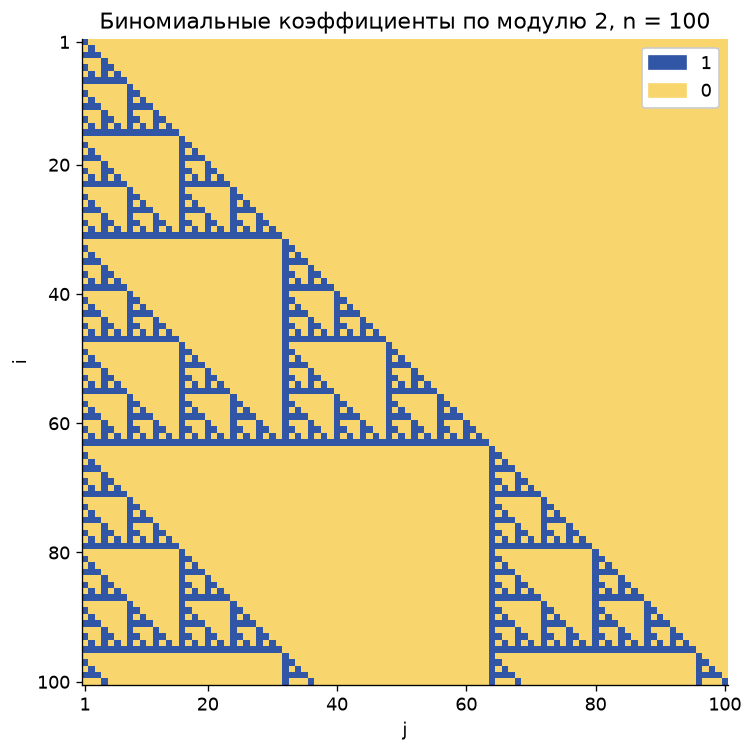

Размер: (100, 100) ; проверено прямым вычислением всех элементов.


In [12]:
indices11 = np.arange(1, 101, dtype=np.int64)
rows11, cols11 = indices11[:, None], indices11[None, :]
parity11 = ((rows11 & cols11) == cols11).astype(np.uint8)
direct11 = np.array([[math.comb(i,j) % 2 if j <= i else 0
                      for j in range(1,101)] for i in range(1,101)], dtype=np.uint8)
assert np.array_equal(parity11, direct11)
assert np.array_equal(parity11[:3,:3], [[1,0,0], [0,1,0], [1,1,1]])

fig, ax = plt.subplots(figsize=(7, 6.4))
ax.imshow(parity11, cmap=ListedColormap(['#f9d66d', '#3156a6']),
          vmin=0, vmax=1, interpolation='nearest', origin='upper',
          extent=(0.5,100.5,100.5,0.5))
ax.set(xticks=[1,20,40,60,80,100], yticks=[1,20,40,60,80,100],
       xlabel='j', ylabel='i', title='Биномиальные коэффициенты по модулю 2, n = 100')
ax.legend(handles=[Patch(color='#3156a6', label='1'), Patch(color='#f9d66d', label='0')],
          loc='upper right', framealpha=1)
fig.tight_layout()
plt.show()
print('Размер:', parity11.shape, '; проверено прямым вычислением всех элементов.')
answers['1.11'] = 'Матрица 100×100 и рисунок; 1 — синий, 0 — жёлтый'

## 1.12. Матрицы Адамара и произведение Кронекера

Выберем стандартное семейство Сильвестра:
$$H_1=(1),\qquad H_2=\begin{pmatrix}1&1\\1&-1\end{pmatrix},\qquad
H_4=\begin{pmatrix}1&1&1&1\\1&-1&1&-1\\1&1&-1&-1\\1&-1&-1&1\end{pmatrix}.$$
По определению произведения Кронекера
$$H_4=H_2\otimes H_2,\qquad
H_{2^k}=H_2\otimes H_{2^{k-1}}
=\begin{pmatrix}H_{2^{k-1}}&H_{2^{k-1}}\\
H_{2^{k-1}}&-H_{2^{k-1}}\end{pmatrix}.$$
Если $HH^T=2^{k-1}I$, то произведение этой блочной матрицы на транспонированную
равно $\operatorname{diag}(2HH^T,2HH^T)=2^kI$. Это доказывает рекурсию
и свойство Адамара по индукции для выбранного семейства.

Условие $H_nH_n^T=nI$ само по себе не задаёт единственную матрицу:
перестановки строк и столбцов могут менять рисунок. Ниже используется
естественный порядок Сильвестра. Построим $H_{64}$: **+1 — оранжевый,
−1 — синий**.

**H₁**

[1]

**H₂**

⎡1  1 ⎤
⎢     ⎥
⎣1  -1⎦

**H₄ = H₂ ⊗ H₂**

⎡1  1   1   1 ⎤
⎢             ⎥
⎢1  -1  1   -1⎥
⎢             ⎥
⎢1  1   -1  -1⎥
⎢             ⎥
⎣1  -1  -1  1 ⎦

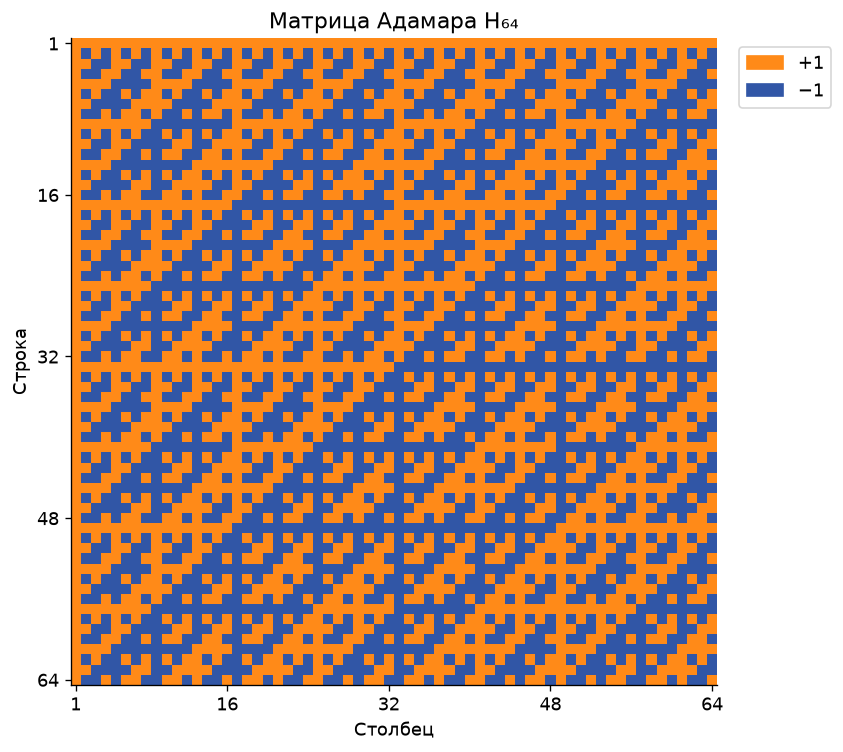

Точная целочисленная проверка: H₆₄ H₆₄ᵀ = 64 I₆₄.


In [13]:
H1 = np.ones((1,1), dtype=np.int64)
H2 = np.array([[1,1], [1,-1]], dtype=np.int64)
H4 = np.kron(H2, H2)
show('H₁', sp.Matrix(H1))
show('H₂', sp.Matrix(H2))
show('H₄ = H₂ ⊗ H₂', sp.Matrix(H4))
H64 = H1.copy()
for _ in range(6):
    H64 = np.kron(H2, H64)
assert np.array_equal(H64 @ H64.T, 64*np.eye(64, dtype=np.int64))
assert set(np.unique(H64)) == {-1, 1}

fig, ax = plt.subplots(figsize=(7, 6.4))
ax.imshow(H64, cmap=ListedColormap(['#3156a6', '#ff8a18']),
          norm=BoundaryNorm([-2,0,2], 2), interpolation='nearest',
          extent=(0.5,64.5,64.5,0.5))
ax.set(xticks=[1,16,32,48,64], yticks=[1,16,32,48,64], xlabel='Столбец',
       ylabel='Строка', title='Матрица Адамара H₆₄')
ax.legend(handles=[Patch(color='#ff8a18', label='+1'), Patch(color='#3156a6', label='−1')],
          bbox_to_anchor=(1.02,1), loc='upper left')
fig.tight_layout()
plt.show()
print('Точная целочисленная проверка: H₆₄ H₆₄ᵀ = 64 I₆₄.')
answers['1.12'] = 'H₁, H₂, H₄; рекурсия Сильвестра; рисунок H₆₄ и проверка ортогональности'

## 1.13. Комплексное собственное значение

$$A=\begin{pmatrix}14&10&21\\12&15&26\\18&11&27\end{pmatrix}.$$
Выберем собственное значение $Z$ с наибольшей мнимой частью.
Соответствующий собственный вектор нормируем первой координатой:
$X=(1,U,V)^T$. Такая нормировка допустима, поскольку первая координата
найденного вектора ненулевая. Проверим невязку $AX-ZX$.

In [14]:
A13_exact = sp.Matrix([[14,10,21], [12,15,26], [18,11,27]])
A13 = np.array(A13_exact, dtype=float)
values13, vectors13 = np.linalg.eig(A13)
index13 = np.argmax(values13.imag)
Z13 = values13[index13]
assert abs(vectors13[0,index13]) > 1e-10
X13 = vectors13[:,index13] / vectors13[0,index13]
residual13 = np.linalg.norm(A13@X13 - Z13*X13)
show('Характеристический многочлен', A13_exact.charpoly().as_expr())
print(f'Z = {Z13.real:.12f} + {Z13.imag:.12f} i')
print('X =', X13)
print(f'Im Z = {Z13.imag:.12f}')
print(f'Re U = {X13[1].real:.12f}')
print(f'||AX − ZX||₂ = {residual13:.3e}')
assert residual13 < 1e-10
assert Z13.imag > 0 and np.isclose(X13[0], 1)
answers['1.13'] = f'Im Z ≈ {Z13.imag:.9f}; Re U ≈ {X13[1].real:.9f}'

**Характеристический многочлен**

Z = 1.968840330802 + 0.344789348427 i
X = [ 1.          -0.j            3.7478197294+1.3308467741j
 -2.3575884268-0.6173180187j]
Im Z = 0.344789348427
Re U = 3.747819729395
||AX − ZX||₂ = 1.996e-14


## 1.14. Минимальный многочлен

$$A=\begin{pmatrix}
-3&7&-6&-1&8&-3&-2\\
1&-5&8&-3&-5&4&-5\\
1&3&-4&6&-2&0&8\\
-1&11&-12&9&3&-3&9\\
-3&11&-12&5&8&-4&6\\
-3&2&1&-4&4&1&-7\\
1&-5&6&-2&-4&3&-2
\end{pmatrix}.$$

Минимальный многочлен — первый монический многочлен $m(t)$,
для которого $m(A)=0$. Будем последовательно искать линейную зависимость
между $I,A,A^2,\ldots$, разворачивая каждую матрицу в столбец длины 49.
Первая зависимость возникает на степени 5:
$$m(t)=t^3(t-1)^2=t^5-2t^4+t^3.$$
Недостаточно только проверить $m(A)=0$: для минимальности также проверим
линейную независимость $I,A,\ldots,A^4$.

In [15]:
A14 = sp.Matrix([
    [-3,7,-6,-1,8,-3,-2], [1,-5,8,-3,-5,4,-5], [1,3,-4,6,-2,0,8],
    [-1,11,-12,9,3,-3,9], [-3,11,-12,5,8,-4,6],
    [-3,2,1,-4,4,1,-7], [1,-5,6,-2,-4,3,-2],
])
z = sp.symbols('t')
powers14 = [sp.eye(7)]
for degree14 in range(1, 8):
    powers14.append(powers14[-1]*A14)
    krylov14 = sp.Matrix.hstack(*(P.reshape(49,1) for P in powers14))
    dependence14 = krylov14.nullspace()
    if dependence14:
        coefficients14 = dependence14[0] / dependence14[0][-1]
        minimal14 = sp.expand(sum(coefficients14[i]*z**i for i in range(degree14+1)))
        break

evaluation14 = sum((coefficients14[i]*powers14[i] for i in range(degree14+1)), sp.zeros(7))
rank_lower14 = krylov14[:,:-1].rank()
assert evaluation14 == sp.zeros(7)
assert rank_lower14 == degree14 == 5
assert sp.expand(minimal14 - z**3*(z-1)**2) == 0
show('Минимальный многочлен', sp.factor(minimal14))
show('Характеристический многочлен', sp.factor(A14.charpoly(z).as_expr()))
print(f'Ранг [vec I, …, vec A⁴] = {rank_lower14}; m(A) = 0.')
answers['1.14'] = 'm(t) = t³(t−1)²'

**Минимальный многочлен**

**Характеристический многочлен**

Ранг [vec I, …, vec A⁴] = 5; m(A) = 0.


## 1.15. Собственный ортонормированный базис

$$A=\begin{pmatrix}17&-8&4\\-8&17&-4\\4&-4&11\end{pmatrix}.$$
Матрица симметрична. Её собственные значения — $9$ (кратность 2) и $27$.
Выберем следующие взаимно ортогональные единичные векторы:
$$e'_1=\frac{(1,1,0)^T}{\sqrt2},\qquad
e'_2=\frac{(1,-1,-4)^T}{3\sqrt2},\qquad
e'_3=\frac{(2,-2,1)^T}{3}.$$
Пусть $P=(e'_1\ e'_2\ e'_3)$. Тогда $x=Py$, $P^TP=I$, а матрица
оператора в новом базисе равна $P^TAP=\operatorname{diag}(9,9,27)$.

In [16]:
A15 = sp.Matrix([[17,-8,4], [-8,17,-4], [4,-4,11]])
P15 = sp.Matrix.hstack(sp.Matrix([1,1,0])/sp.sqrt(2),
                      sp.Matrix([1,-1,-4])/(3*sp.sqrt(2)),
                      sp.Matrix([2,-2,1])/3)
D15 = sp.simplify(P15.T*A15*P15)
assert sp.simplify(P15.T*P15) == sp.eye(3)
assert D15 == sp.diag(9,9,27)
assert sp.simplify(A15*P15 - P15*D15) == sp.zeros(3)
show('Матрица перехода P (столбцы — новый базис)', P15)
show('Матрица оператора в новом базисе', D15)
answers['1.15'] = 'Ортонормированный базис приведён выше; D = diag(9,9,27)'

**Матрица перехода P (столбцы — новый базис)**

⎡√2    √2        ⎤
⎢──    ──    2/3 ⎥
⎢2     6         ⎥
⎢                ⎥
⎢√2   -√2        ⎥
⎢──   ────   -2/3⎥
⎢2     6         ⎥
⎢                ⎥
⎢    -2⋅√2       ⎥
⎢0   ──────  1/3 ⎥
⎣      3         ⎦

**Матрица оператора в новом базисе**

⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦

## 1.16. Приведение к главным осям

$$f=3x_1^2+8x_1x_2-3x_2^2+4x_3^2-4x_3x_4+x_4^2.$$
Матрица формы состоит из двух независимых симметричных блоков:
$$A=\begin{pmatrix}3&4&0&0\\4&-3&0&0\\0&0&4&-2\\0&0&-2&1\end{pmatrix}.$$
Выберем ортогональное преобразование $x=Py$:
$$P=\frac1{\sqrt5}\begin{pmatrix}
2&0&1&0\\1&0&-2&0\\0&2&0&1\\0&-1&0&2
\end{pmatrix}.$$
Тогда $P^TAP=\operatorname{diag}(5,5,-5,0)$ и
$$f=5y_1^2+5y_2^2-5y_3^2.$$
Форма вырожденная и неопределённая; инерция $(n_+,n_-,n_0)=(2,1,1)$.

In [17]:
A16 = sp.Matrix([[3,4,0,0], [4,-3,0,0], [0,0,4,-2], [0,0,-2,1]])
P16 = sp.Matrix([[2,0,1,0], [1,0,-2,0], [0,2,0,1], [0,-1,0,2]])/sp.sqrt(5)
D16 = sp.simplify(P16.T*A16*P16)
assert sp.simplify(P16.T*P16) == sp.eye(4)
assert D16 == sp.diag(5,5,-5,0)
y16 = sp.Matrix(sp.symbols('y1:5', real=True))
canonical16 = sp.expand(((P16*y16).T*A16*(P16*y16))[0])
show('PᵀAP', D16)
show('Каноническая форма', canonical16)
answers['1.16'] = '5y₁² + 5y₂² − 5y₃²; x = Py; инерция (2,1,1)'

**PᵀAP**

⎡5  0  0   0⎤
⎢           ⎥
⎢0  5  0   0⎥
⎢           ⎥
⎢0  0  -5  0⎥
⎢           ⎥
⎣0  0  0   0⎦

**Каноническая форма**

## 1.17. Кривые второго порядка

### а) $5x^2+4xy+8y^2-32x-56y+80=0$

Центр кривой — $(2,3)$. После переноса начала координат квадратичная часть
имеет собственные значения 4 и 9. Поворот с единичными осями
$(2,-1)/\sqrt5$, $(1,2)/\sqrt5$ задаётся формулами
$$x=2+\frac{2u+v}{\sqrt5},\qquad y=3+\frac{-u+2v}{\sqrt5}.$$
Получаем $4u^2+9v^2-36=0$, то есть **эллипс**
$$\boxed{\frac{u^2}{9}+\frac{v^2}{4}=1}.$$
Полуоси равны 3 и 2.

### б) $5x^2+12xy-22x-12y-19=0$

Центр — $(1,1)$, собственные значения квадратичной части — 9 и $-4$.
Выберем оси $(3,2)/\sqrt{13}$, $(-2,3)/\sqrt{13}$:
$$x=1+\frac{3u-2v}{\sqrt{13}},\qquad
y=1+\frac{2u+3v}{\sqrt{13}}.$$
Получаем $9u^2-4v^2-36=0$, то есть **гипербола**
$$\boxed{\frac{u^2}{4}-\frac{v^2}{9}=1}.$$
Действительная полуось равна 2, мнимая — 3.

**а) После замены координат**

**б) После замены координат**

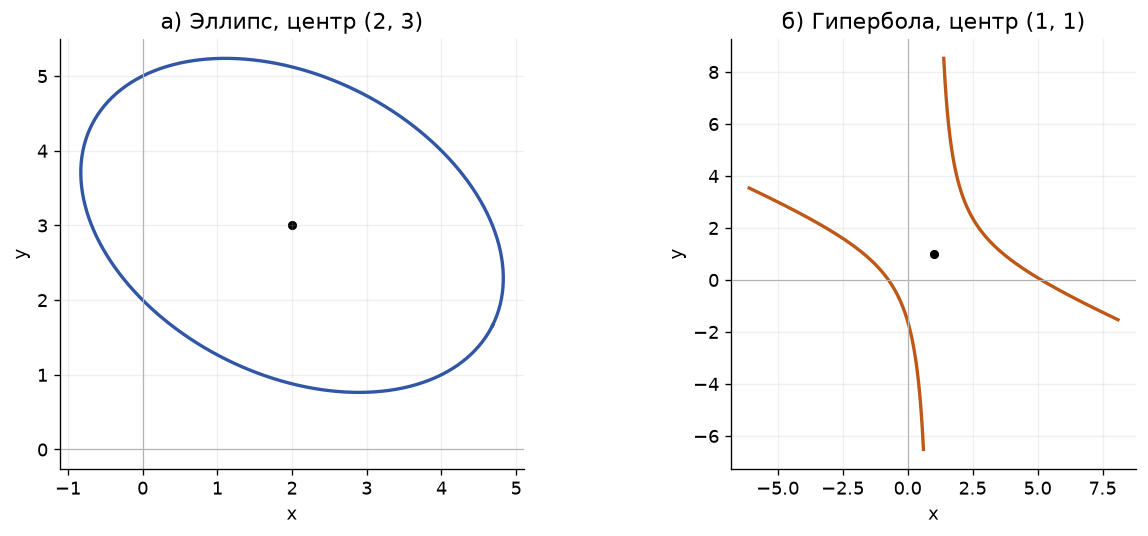

In [18]:
x17, y17, u17, v17 = sp.symbols('x y u v', real=True)
original17a = 5*x17**2+4*x17*y17+8*y17**2-32*x17-56*y17+80
original17b = 5*x17**2+12*x17*y17-22*x17-12*y17-19
rotation17a = sp.Matrix([[2,1], [-1,2]])/sp.sqrt(5)
rotation17b = sp.Matrix([[3,-2], [2,3]])/sp.sqrt(13)
new17a = sp.Matrix([2,3]) + rotation17a*sp.Matrix([u17,v17])
new17b = sp.Matrix([1,1]) + rotation17b*sp.Matrix([u17,v17])
transformed17a = sp.expand(original17a.subs({x17:new17a[0], y17:new17a[1]}, simultaneous=True))
transformed17b = sp.expand(original17b.subs({x17:new17b[0], y17:new17b[1]}, simultaneous=True))
assert transformed17a == 4*u17**2+9*v17**2-36
assert transformed17b == 9*u17**2-4*v17**2-36
for rotation in [rotation17a, rotation17b]:
    assert sp.simplify(rotation.T*rotation) == sp.eye(2)
    assert sp.simplify(rotation.det()) == 1
show('а) После замены координат', transformed17a)
show('б) После замены координат', transformed17b)

fig, axes = plt.subplots(1,2,figsize=(11,4.6))
angle17 = np.linspace(0,2*np.pi,500)
ellipse17 = np.array(rotation17a, dtype=float) @ np.vstack([3*np.cos(angle17),2*np.sin(angle17)])
ellipse17 += np.array([[2],[3]])
axes[0].plot(*ellipse17, color='#3156a6', lw=2)
axes[0].scatter([2],[3], color='black', s=20)
axes[0].set_title('а) Эллипс, центр (2, 3)')
parameter17 = np.linspace(-1.45,1.45,400)
for sign in [-1,1]:
    branch17 = np.array(rotation17b, dtype=float) @ np.vstack([sign*2*np.cosh(parameter17),3*np.sinh(parameter17)])
    branch17 += np.array([[1],[1]])
    axes[1].plot(*branch17, color='#bd5817', lw=2)
axes[1].scatter([1],[1], color='black', s=20)
axes[1].set_title('б) Гипербола, центр (1, 1)')
for ax in axes:
    ax.axhline(0,color='0.7',lw=0.7)
    ax.axvline(0,color='0.7',lw=0.7)
    ax.set(xlabel='x',ylabel='y',aspect='equal')
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
answers['1.17'] = 'а) эллипс: u²/9+v²/4=1; б) гипербола: u²/4−v²/9=1'

## 1.18. Положительная определённость

$$Q=x_1^2+4x_2^2+x_3^2+2\lambda x_1x_2+10x_1x_3+6x_2x_3.$$
Уже на ненулевом векторе $(1,0,-1)$ при любом $\lambda$:
$$Q(1,0,-1)=1+1-10=-8<0.$$
Поэтому форма **не является положительно определённой ни при одном
вещественном $\lambda$**. Это согласуется с отрицательным главным минором
по индексам $(1,3)$: $1\cdot1-5^2=-24$.

In [19]:
lam = sp.symbols('lambda', real=True)
A18 = sp.Matrix([[1,lam,5], [lam,4,3], [5,3,1]])
witness18 = sp.Matrix([1,0,-1])
value18 = (witness18.T*A18*witness18)[0]
show('Q(1, 0, −1)', value18)
show('Главный минор по индексам (1, 3)', A18.extract([0,2],[0,2]).det())
assert value18 == -8
print('Множество допустимых параметров: пустое.')
answers['1.18'] = 'Нет таких вещественных λ'

**Q(1, 0, −1)**

**Главный минор по индексам (1, 3)**

Множество допустимых параметров: пустое.


## 1.19. Отрицательная определённость

$$Q=\lambda x_1^2-2x_2^2-3x_3^2+2x_1x_2-2x_1x_3+2x_2x_3.$$
По критерию Сильвестра для отрицательной определённости требуется
$\Delta_1<0$, $\Delta_2>0$, $\Delta_3<0$.
В данном случае
$$\Delta_1=\lambda,\qquad \Delta_2=-2\lambda-1,\qquad
\Delta_3=5\lambda+3.$$
Пересечение условий даёт **$\lambda<-3/5$**.
Граничное значение не включается: при $\lambda=-3/5$ определитель равен нулю.

In [20]:
A19 = sp.Matrix([[lam,1,-1], [1,-2,1], [-1,1,-3]])
minors19 = [sp.factor(A19[:i,:i].det()) for i in range(1,4)]
conditions19 = [minors19[0] < 0, minors19[1] > 0, minors19[2] < 0]
solution19 = sp.reduce_inequalities(conditions19, lam)
show('Угловые миноры', sp.Matrix(minors19))
show('Решение системы неравенств', solution19)
assert A19.subs(lam, -1).is_negative_definite
assert A19.subs(lam, -sp.Rational(3,5)).det() == 0
answers['1.19'] = 'λ < −3/5'

**Угловые миноры**

⎡   λ    ⎤
⎢        ⎥
⎢-2⋅λ - 1⎥
⎢        ⎥
⎣5⋅λ + 3 ⎦

**Решение системы неравенств**

## 1.20. Эквивалентность квадратичных форм

В условии записано
$$Q_1=2x_1^2+9x_2^2+3x_3^2+8x_1x_2-4x_1x_3-10x_2x_3,$$
$$Q_2=2x_1+3x_2^2+6x_3^2-4x_1x_2-4x_1x_3+8x_2x_3.$$

**Буквальная запись PDF.** У $Q_2$ есть линейное слагаемое $2x_1$,
поэтому это не квадратичная форма. При обратимой линейной замене переменных
ненулевая линейная часть остаётся ненулевой. В таком прочтении $Q_2$
невозможно получить из однородной формы $Q_1$ обратимой линейной заменой.

**Если в первом слагаемом $Q_2$ подразумевалось $2x_1^2$.** Тогда
$$Q_1=2(x_1+2x_2-x_3)^2+(x_2-x_3)^2,$$
$$\widetilde Q_2=2(x_1-x_2-x_3)^2+(x_2+2x_3)^2.$$
В обоих случаях замены внутри квадратов можно дополнить третьей
координатой $x_3$; соответствующие треугольные матрицы обратимы.
Обе формы приводятся к $2y_1^2+y_2^2$ и имеют инерцию $(2,0,1)$.
По закону инерции Сильвестра они **эквивалентны над $\mathbb R$**.
Ниже найдена и проверена явная матрица $S$ такая, что
$Q_1(Sx)=\widetilde Q_2(x)$.

In [21]:
A20_1 = sp.Matrix([[2,4,-2], [4,9,-5], [-2,-5,3]])
A20_2 = sp.Matrix([[2,-2,-2], [-2,3,4], [-2,4,6]])
T20_1 = sp.Matrix([[1,2,-1], [0,1,-1], [0,0,1]])
T20_2 = sp.Matrix([[1,-1,-1], [0,1,2], [0,0,1]])
D20 = sp.diag(2,1,0)
assert A20_1 == T20_1.T*D20*T20_1
assert A20_2 == T20_2.T*D20*T20_2
S20 = T20_1.inv()*T20_2
assert S20.det() != 0
assert S20.T*A20_1*S20 == A20_2
show('S: Q₁(Sx) = Q̃₂(x)', S20)
show('Sᵀ A₁ S', S20.T*A20_1*S20)
print('Для квадратичной трактовки: обе инерции (2, 0, 1); формы эквивалентны.')
print('Для буквальной записи с 2x₁: второе выражение не является квадратичной формой.')
answers['1.20'] = 'С 2x₁²: эквивалентны, инерция (2,0,1). С 2x₁: не квадратичная форма'

**S: Q₁(Sx) = Q̃₂(x)**

⎡1  -3  -6⎤
⎢         ⎥
⎢0  1   3 ⎥
⎢         ⎥
⎣0  0   1 ⎦

**Sᵀ A₁ S**

⎡2   -2  -2⎤
⎢          ⎥
⎢-2  3   4 ⎥
⎢          ⎥
⎣-2  4   6 ⎦

Для квадратичной трактовки: обе инерции (2, 0, 1); формы эквивалентны.
Для буквальной записи с 2x₁: второе выражение не является квадратичной формой.


## Таблица результатов

Все 20 заданий выполнены. В точных задачах использована рациональная
арифметика; округление применено только при выводе численных ответов.
Числа в заданиях 1.7–1.9 совпадают с контрольными ответами листка
после округления.

In [22]:
assert list(answers) == [f'1.{i}' for i in range(1,21)]
summary = '| Задание | Ответ |\n|:---:|:---|\n'
summary += '\n'.join(f'| {number} | {answer} |' for number,answer in answers.items())
display(Markdown(summary))
print('Выполнено 20 из 20 заданий; все проверки завершились успешно.')

| Задание | Ответ |
|:---:|:---|
| 1.1 | (-(11+8t)/7, (-6+2t)/7, (4+t)/7, t) |
| 1.2 | (4−2s−3t, 7−5s−6t, s, t, 8) |
| 1.3 | a = 14027, b = -4262 |
| 1.4 | [[7, 4, 5, 11], [6, 4, -1, 6], [0, 0, 6, 12], [-1, 2, 1, 3]] |
| 1.5 | 1; (−1)^(n−1)n; (−1)^(n−1)(n−1)2^(n−2), n≥2 (при n=1: 0) |
| 1.6 | 160 |
| 1.7 | det A ≈ 0.258979114; tr(A⁻¹) ≈ 80002.702766 |
| 1.8 | min B ≈ -1.028037383; сумма ≈ -2054.438267 |
| 1.9 | 3.609679; 3.611175; k = 89 |
| 1.10 | a = 16, b = −116 (c = 576) |
| 1.11 | Матрица 100×100 и рисунок; 1 — синий, 0 — жёлтый |
| 1.12 | H₁, H₂, H₄; рекурсия Сильвестра; рисунок H₆₄ и проверка ортогональности |
| 1.13 | Im Z ≈ 0.344789348; Re U ≈ 3.747819729 |
| 1.14 | m(t) = t³(t−1)² |
| 1.15 | Ортонормированный базис приведён выше; D = diag(9,9,27) |
| 1.16 | 5y₁² + 5y₂² − 5y₃²; x = Py; инерция (2,1,1) |
| 1.17 | а) эллипс: u²/9+v²/4=1; б) гипербола: u²/4−v²/9=1 |
| 1.18 | Нет таких вещественных λ |
| 1.19 | λ < −3/5 |
| 1.20 | С 2x₁²: эквивалентны, инерция (2,0,1). С 2x₁: не квадратичная форма |

Выполнено 20 из 20 заданий; все проверки завершились успешно.
